# Week 10: Visualization (part 2) + GIS data
## Name: Bria Pickel-Fridman
## 11/2/2026

In [1]:

# first we need to import our visualization libraries and any other related components

import json # need to parse geojson
import re # needed for wordcloud example

import matplotlib.pyplot as plt # 
import pandas as pd # using data frames with our plotly visualization
import plotly.express as px # px shorthand is used in plotly examples
import pydeck as pdk # pdk is used as a shorthand for pydeck examples

from IPython.display import HTML, IFrame # needed to display pydeck visualization in the notebook
from wordcloud import STOPWORDS, wordcloud #


## Visualizing as poll data

I have included two files (`house_average_recent.csv` and `senate_average_recent.csv`) which contain average polls for seante and house races for the 2026 US election. Firt we want to load these as a dataframe:

In [2]:
house = pd.read_csv("house_average_recent.csv")
senate = pd.read_csv("senate_average_recent.csv")

In [3]:

#preview what's in each file:
house.head()

,id,state,district,dem,rep,margin,polls,latest,days_old
0,AK-1,AK,1,5.8,45.8,-40.1,1,2026-10-30,1
1,AL-2,AL,2,45.0,49.5,-4.5,1,2026-10-25,6
2,AR-2,AR,2,48.0,52.0,-4.0,1,2026-10-14,17
3,AZ-1,AZ,1,49.4,45.0,4.4,1,2026-10-28,3
4,AZ-2,AZ,2,50.0,48.0,2.0,1,2026-10-14,17


In [4]:
senate.head()

,state,dem,rep,margin,polls,latest,days_old
0,AK,48.7,47.1,1.6,2,2026-10-30,2
1,AL,39.5,47.8,-8.3,1,2026-10-24,8
2,AR,39.0,55.0,-16.0,1,2026-10-28,4
3,FL,43.6,49.3,-5.7,7,2026-10-30,2
4,GA,53.9,43.8,10.1,3,2026-10-23,9


Since our data doesn't cleanly add up to 100% for each senate/house poll average, we need to calculate a 3rd value for "other" to make up for the missing points!

other = 100 - dem - rep

In [5]:
senate["other"]=(100-senate["dem"]-senate["rep"]).clip(lower=0).round(1)

In [16]:
senate.head()

,state,dem,rep,margin,polls,latest,days_old,other
0,AK,48.7,47.1,1.6,2,2026-10-30,2,4.2
1,AL,39.5,47.8,-8.3,1,2026-10-24,8,12.7
2,AR,39.0,55.0,-16.0,1,2026-10-28,4,6.0
3,FL,43.6,49.3,-5.7,7,2026-10-30,2,7.1
4,GA,53.9,43.8,10.1,3,2026-10-23,9,2.3


In [7]:
# a dictionary of the names we want in the legend: {old column name: new name}
party_names = {"dem": "Democrat", "other": "Other / undecided", "rep": "Republican"}

# the color of each bar segment, by its new name 
colors = {"Democrat": "blue", "Other / undecided": "grey", "Republican": "red"}

# sort the states from the smallest margin (most Republican) to the largest (most Democratic),
# and rename the columns using the dictionary above
senate_sorted = senate.sort_values("margin").rename(columns=party_names)

senate_sorted.head()

,state,Democrat,Republican,margin,polls,latest,days_old,Other / undecided
6,ID,13.0,43.0,-30.0,1,2026-07-30,94,44.0
25,SD,18.0,43.0,-25.0,1,2026-05-30,155,39.0
22,OK,26.0,48.5,-22.5,1,2026-08-06,87,25.5
26,TN,32.0,54.5,-22.5,1,2026-08-26,67,13.5
16,MT,17.4,37.9,-20.5,3,2026-10-23,9,44.7


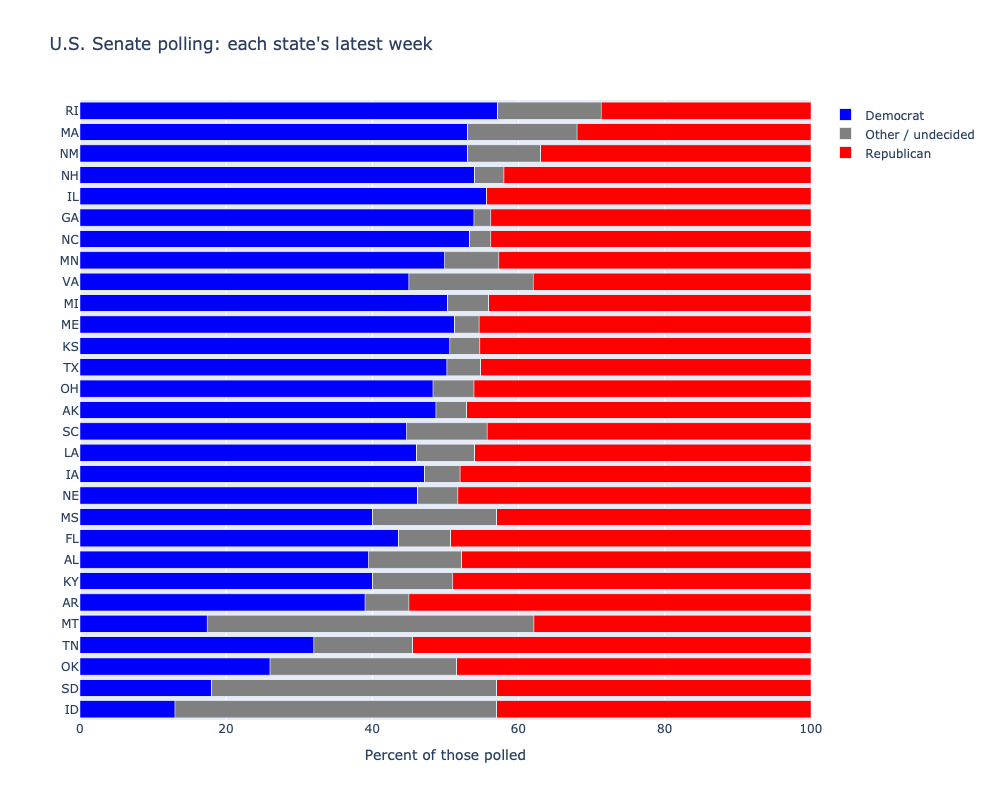

In [8]:
# bar graph method in plotly library
fig = px.bar(
    senate_sorted,
    x=["Democrat", "Other / undecided", "Republican"],   # a list of columns: each one becomes a segment, stacked left to right
    y="state",                                           # one bar for each state
    orientation="h",                                     # "h" for horizontal bars
    color_discrete_map=colors,                           # which color goes with which segment
    labels={"value": "Percent", "state": "State"},       # px calls the length of each segment "value" in the hover box
    hover_data={"polls": True, "latest": True},          # also show the number of polls and the latest poll date
    height=800,                                          # tall enough for 29 bars
    title="U.S. Senate polling: each state's latest week",
)

fig.update_layout(
    legend_title_text="",                  # remove the legend's default title
    xaxis_title="Percent of those polled",
    xaxis_range=[0, 100],                  # always show the full 0 to 100 percent
    yaxis_title="",
    yaxis={"dtick": 1},                    # label every bar (otherwise Plotly may label every other one)
)

fig.show()

## plotting the data on a map!

We can generate a geographic map using our dats, combining it with region shapes (states, congressional districts, etc)
Plotly contains US state outlines by default so we don't need to add them

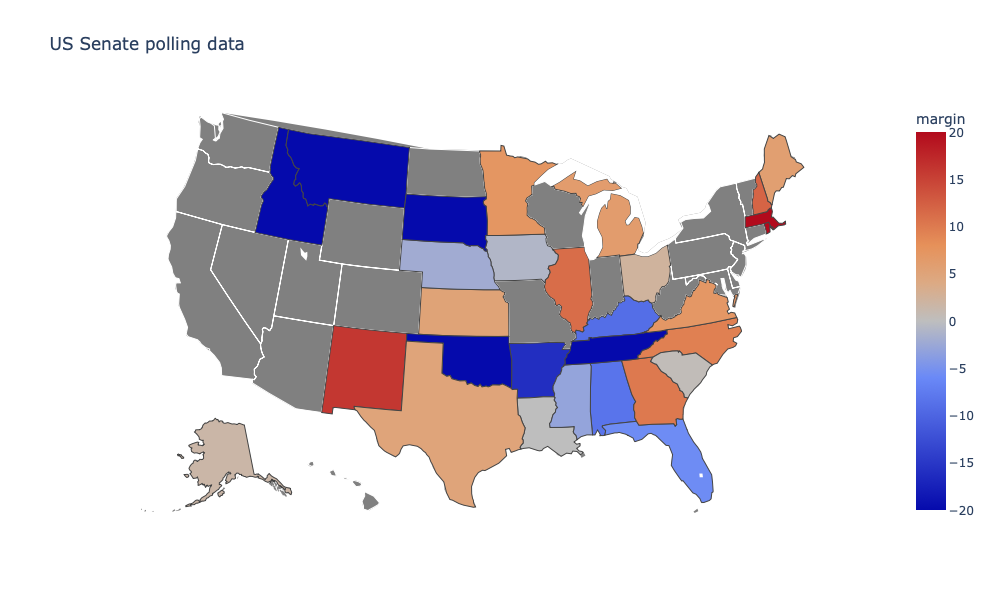

In [15]:
red = "214,40,40" # this is the RGB representation of red
blue = "30, 80, 216" #RGB representation of blue

# we can define a color scale by which our data will be represented

color_scale = [
    [0.0, f"rgba({red}, 1)"], # 1 is most opaque for the "a" value of rgba color
    [0.5,f"rgba({red}, 0.2)"], # 0.2 will read as barely opaque
    [0.5,f"rgba({blue}, 0.2)"],
    [0.0, f"rgba({blue}, 1)"]
]


colorbar = {
    "title": "Lead by margin",
    "tickvals": [-20, -10, 0, 10, 20],
    "ticktext": ["R+20", "R+10", "Tie" "D+10" "D+20"]
}

fig = px.choropleth(
    senate,
    locations="state", # this tells the ployly library which column of our data contains location information
    locationmode = "USA-states", # this tells plotly that we are dealing with US state data and to plot accordingly
    scope="usa", #zooms in on the US
    color="margin", # give color to each region based on "Margin" column of dataset
    color_continuous_scale = color_scale, # references the color scale we made in the beginning of the block
    range_color=[-20,20],
    height=600,
    title="US Senate polling data"
)

fig.update_geos(landcolor="grey")

fig.show()